## CÂU 4. TÁCH THUỘC TÍNH ĐẦU VÀO X VÀ THUỘC TÍNH QUYẾT ĐỊNH y

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Đọc dữ liệu
data = pd.read_csv('/content/mushrooms.csv')

print("Kích thước dữ liệu:", data.shape)
display(data.head())

# Tách thuộc tính đầu vào X và thuộc tính quyết định y
X = data.drop(columns=['class'])
y = data['class']

print("\nKích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nSố lượng từng lớp:")
print(y.value_counts())

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Kích thước dữ liệu: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Kích thước X: (8124, 22)
Kích thước y: (8124,)

Số lượng từng lớp:
class
e    4208
p    3916
Name: count, dtype: int64


## CÂU 5. MÃ HÓA CÁC THUỘC TÍNH KHÔNG PHẢI DẠNG SỐ

In [2]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# One-Hot Encoding các thuộc tính đầu vào
X_encoded = pd.get_dummies(X, dtype=int)

print("Kích thước X ban đầu:", X.shape)
print("Kích thước X sau mã hóa:", X_encoded.shape)

print("\n5 dòng dữ liệu sau mã hóa:")
display(X_encoded.head())

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Kích thước X ban đầu: (8124, 22)
Kích thước X sau mã hóa: (8124, 117)

5 dòng dữ liệu sau mã hóa:


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## CÂU 6. CHIA DỮ LIỆU HUẤN LUYỆN VÀ KIỂM THỬ

In [3]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Chia dữ liệu thành tập huấn luyện và kiểm thử
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.3,
    random_state=42
)

print("Kích thước tập huấn luyện:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nKích thước tập kiểm thử:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Kích thước tập huấn luyện:
X_train: (5686, 117)
y_train: (5686,)

Kích thước tập kiểm thử:
X_test: (2438, 117)
y_test: (2438,)


## CÂU 7. XÂY DỰNG CÂY QUYẾT ĐỊNH ID3 (ENTROPY)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
ĐỘ CHÍNH XÁC ID3: 100.0 %

BÁO CÁO PHÂN LOẠI:
                 precision    recall  f1-score   support

Nấm ăn được (e)       1.00      1.00      1.00      1257
    Nấm độc (p)       1.00      1.00      1.00      1181

       accuracy                           1.00      2438
      macro avg       1.00      1.00      1.00      2438
   weighted avg       1.00      1.00      1.00      2438



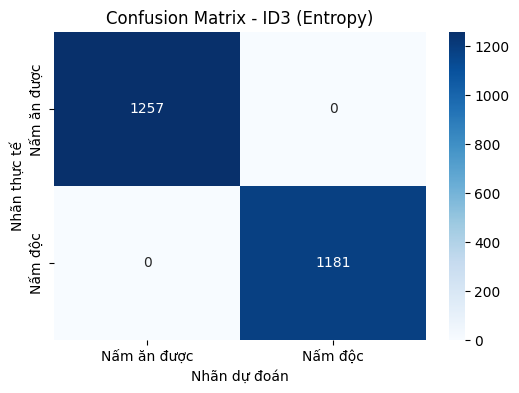

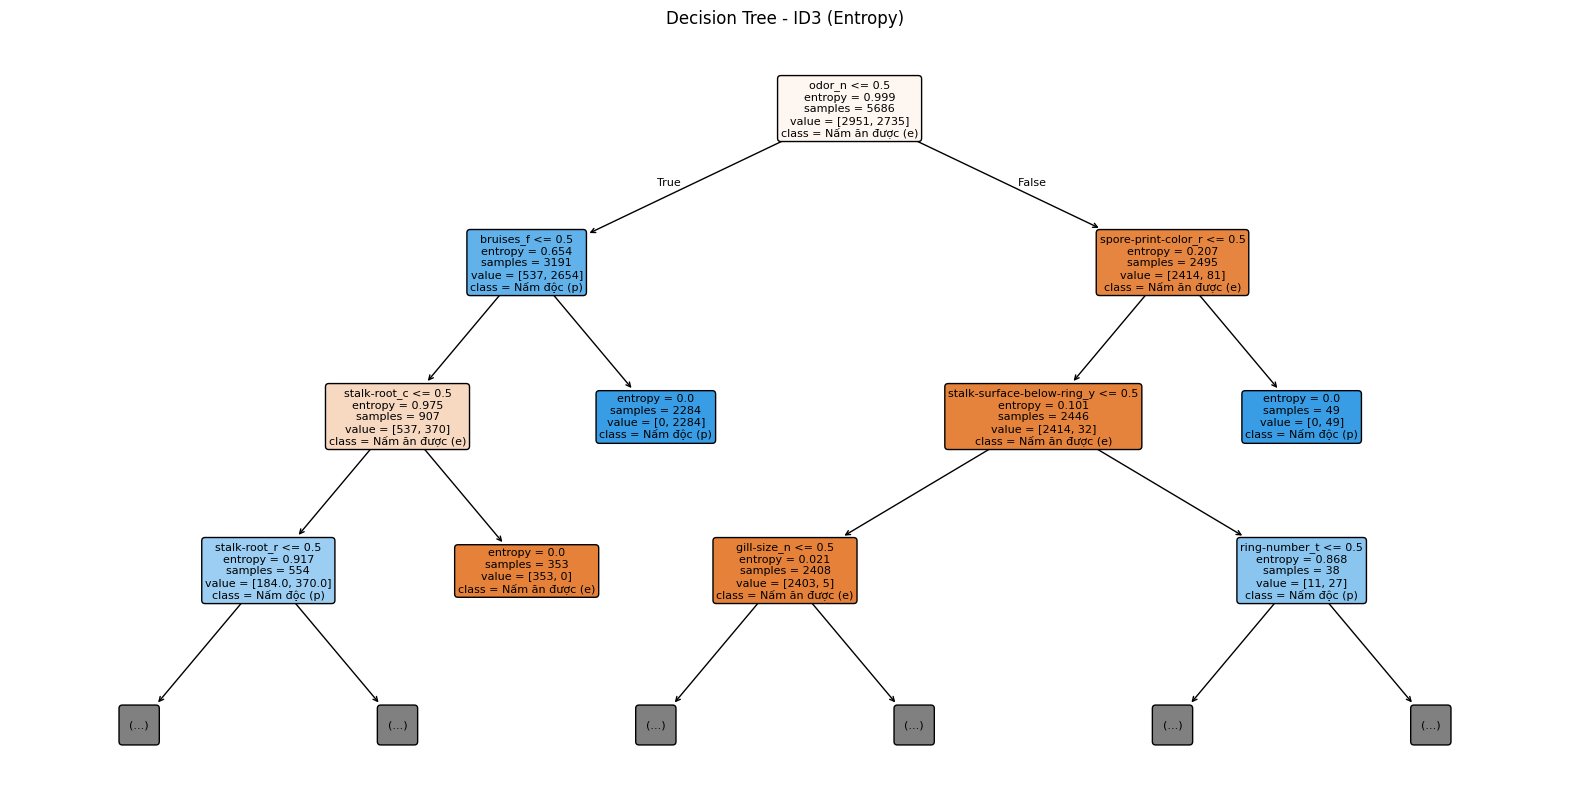

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# 1. Xây dựng và huấn luyện cây quyết định ID3
clf_id3 = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

clf_id3.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_id3 = clf_id3.predict(X_test)

# 3. Đánh giá mô hình
accuracy_id3 = accuracy_score(y_test, y_pred_id3)

print("ĐỘ CHÍNH XÁC ID3:", round(accuracy_id3 * 100, 2), "%")

print("\nBÁO CÁO PHÂN LOẠI:")
print(classification_report(
    y_test,
    y_pred_id3,
    target_names=['Nấm ăn được (e)', 'Nấm độc (p)'],
    zero_division=0
))

# 4. Ma trận nhầm lẫn
cm_id3 = confusion_matrix(y_test, y_pred_id3, labels=['e', 'p'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_id3,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Nấm ăn được', 'Nấm độc'],
    yticklabels=['Nấm ăn được', 'Nấm độc']
)

plt.title('Confusion Matrix - ID3 (Entropy)')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thực tế')
plt.show()

# 5. Biểu diễn cây quyết định (3 tầng đầu)
plt.figure(figsize=(20, 10))
plot_tree(
    clf_id3,
    feature_names=X_train.columns,
    class_names=['Nấm ăn được (e)', 'Nấm độc (p)'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title('Decision Tree - ID3 (Entropy)')
plt.show()

## CÂU 8. XÂY DỰNG CÂY QUYẾT ĐỊNH CART (GINI)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
ĐỘ CHÍNH XÁC CART: 100.0 %

BÁO CÁO PHÂN LOẠI:
                 precision    recall  f1-score   support

Nấm ăn được (e)       1.00      1.00      1.00      1257
    Nấm độc (p)       1.00      1.00      1.00      1181

       accuracy                           1.00      2438
      macro avg       1.00      1.00      1.00      2438
   weighted avg       1.00      1.00      1.00      2438



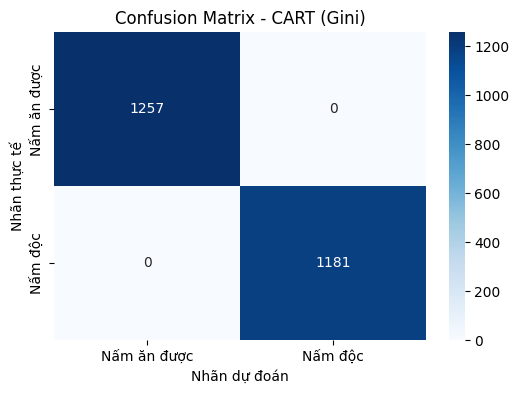

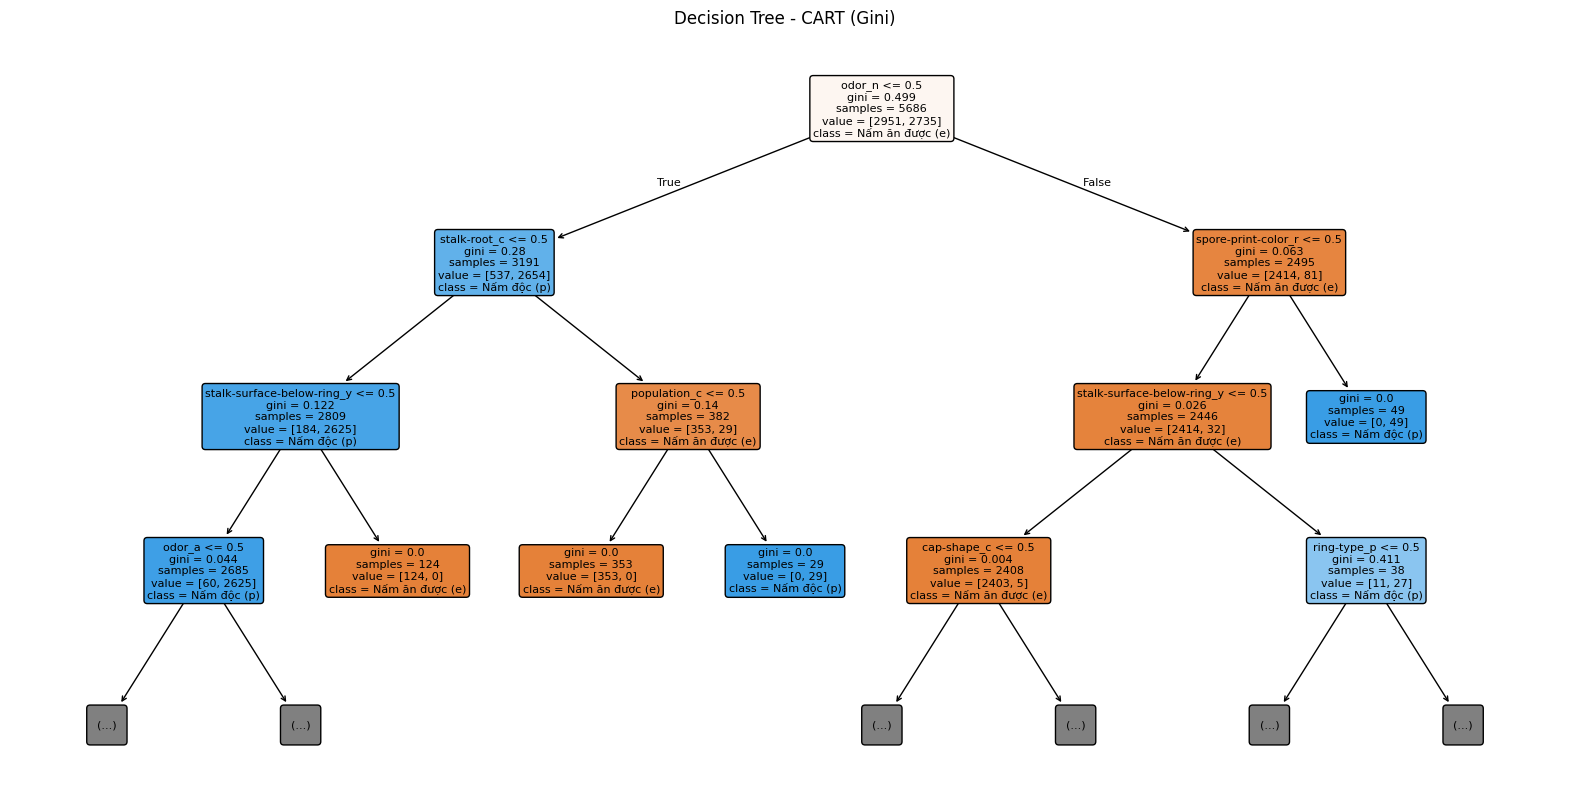

In [5]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# 1. Xây dựng và huấn luyện cây quyết định CART
clf_cart = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

clf_cart.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_cart = clf_cart.predict(X_test)

# 3. Đánh giá mô hình
accuracy_cart = accuracy_score(y_test, y_pred_cart)

print("ĐỘ CHÍNH XÁC CART:", round(accuracy_cart * 100, 2), "%")

print("\nBÁO CÁO PHÂN LOẠI:")
print(classification_report(
    y_test,
    y_pred_cart,
    target_names=['Nấm ăn được (e)', 'Nấm độc (p)'],
    zero_division=0
))

# 4. Ma trận nhầm lẫn
cm_cart = confusion_matrix(y_test, y_pred_cart, labels=['e', 'p'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_cart,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Nấm ăn được', 'Nấm độc'],
    yticklabels=['Nấm ăn được', 'Nấm độc']
)

plt.title('Confusion Matrix - CART (Gini)')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thực tế')
plt.show()

# 5. Biểu diễn cây quyết định (3 tầng đầu)
plt.figure(figsize=(20, 10))
plot_tree(
    clf_cart,
    feature_names=X_train.columns,
    class_names=['Nấm ăn được (e)', 'Nấm độc (p)'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title('Decision Tree - CART (Gini)')
plt.show()

## CÂU 9. XÂY DỰNG MÔ HÌNH NAIVE BAYES

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
ĐỘ CHÍNH XÁC NAIVE BAYES: 96.43 %

BÁO CÁO PHÂN LOẠI:
                 precision    recall  f1-score   support

Nấm ăn được (e)       1.00      0.93      0.96      1257
    Nấm độc (p)       0.93      1.00      0.96      1181

       accuracy                           0.96      2438
      macro avg       0.97      0.97      0.96      2438
   weighted avg       0.97      0.96      0.96      2438



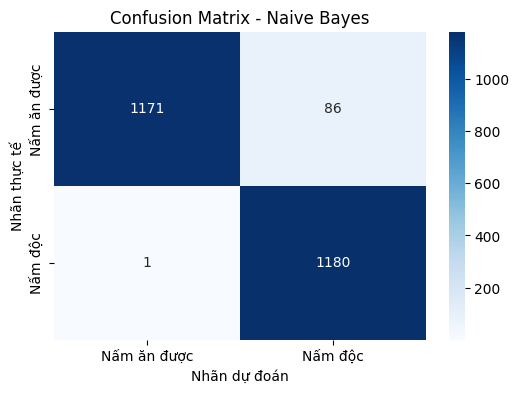

In [6]:
from sklearn.naive_bayes import GaussianNB

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# 1. Xây dựng và huấn luyện mô hình Naive Bayes
clf_nb = GaussianNB()
clf_nb.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_nb = clf_nb.predict(X_test)

# 3. Đánh giá mô hình
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("ĐỘ CHÍNH XÁC NAIVE BAYES:", round(accuracy_nb * 100, 2), "%")

print("\nBÁO CÁO PHÂN LOẠI:")
print(classification_report(
    y_test,
    y_pred_nb,
    labels=['e', 'p'],
    target_names=['Nấm ăn được (e)', 'Nấm độc (p)'],
    zero_division=0
))

# 4. Ma trận nhầm lẫn
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=['e', 'p'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Nấm ăn được', 'Nấm độc'],
    yticklabels=['Nấm ăn được', 'Nấm độc']
)

plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thực tế')
plt.show()

## CÂU 10. SO SÁNH VÀ ĐÁNH GIÁ CÁC MÔ HÌNH

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089


,Mô hình,Accuracy (%)
0,ID3 (Entropy),100.00
1,CART (Gini),100.00
2,Naive Bayes,96.43


Mô hình có độ chính xác cao nhất: ID3 (Entropy)
Accuracy: 100.0 %


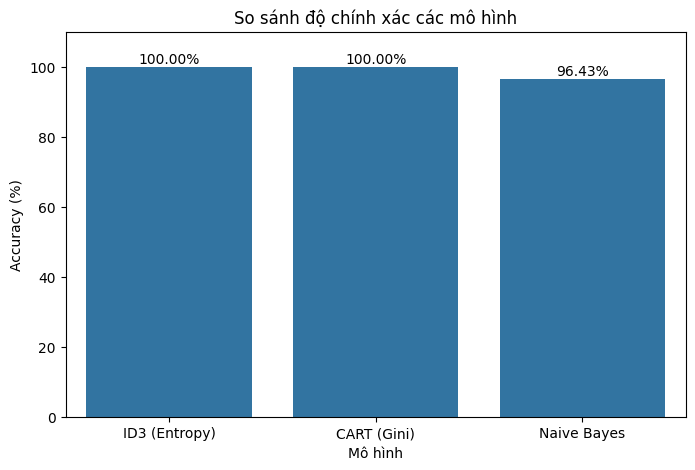

In [7]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# 1. Tổng hợp kết quả các mô hình
results = pd.DataFrame({
    'Mô hình': ['ID3 (Entropy)', 'CART (Gini)', 'Naive Bayes'],
    'Accuracy (%)': [
        accuracy_id3 * 100,
        accuracy_cart * 100,
        accuracy_nb * 100
    ]
})

display(results.round(2))

# 2. Xác định mô hình có độ chính xác cao nhất
best_model = results.loc[results['Accuracy (%)'].idxmax()]

print("Mô hình có độ chính xác cao nhất:", best_model['Mô hình'])
print("Accuracy:", round(best_model['Accuracy (%)'], 2), "%")

# 3. Biểu đồ so sánh
plt.figure(figsize=(8, 5))
sns.barplot(
    data=results,
    x='Mô hình',
    y='Accuracy (%)'
)

plt.title('So sánh độ chính xác các mô hình')
plt.xlabel('Mô hình')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 110)

for i, value in enumerate(results['Accuracy (%)']):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

**Xhận xét**

Qua kết quả thực nghiệm, mô hình ID3 (Entropy) và CART (Gini) đều đạt độ chính xác 100%, cao nhất trong ba mô hình. Mô hình Naive Bayes đạt 96,43%, thấp hơn hai mô hình còn lại. Nhìn chung, cả ba mô hình đều phân loại tốt hai loại nấm ăn được và nấm độc trên tập kiểm thử. Trong đó, ID3 và CART cho kết quả tốt nhất trong lần thực nghiệm này.